<a href="https://colab.research.google.com/github/TildeSkar/Applied-Deep-Learning---Physics---exrecises/blob/main/Exercise_6_4_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exercise 6.4**

MNIST with fully connected networks and grid/random search

In [105]:
import matplotlib.pyplot as plt
import numpy as np
import os
import tensorflow as tf
from tabulate import tabulate
from tensorflow.keras import layers

# For approximate reproducibility
tf.keras.utils.set_random_seed(42)

plt.style.use("seaborn-v0_8")
plt.rcParams.update({"image.cmap": "viridis"})

The MNIST data base of handwritten numbers is directly available through KERAS. The following codeblocks download and preprocess the data.

In [106]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_valid = x_test[8000:]
y_valid = y_test[8000:]
x_test = x_test[:8000]
y_test = y_test[:8000]

# Hint: convert integer RGB values (0-255) to float values (0-1)


In [107]:
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_valid.shape[0], "validation samples")
print(x_test.shape[0], "test samples")

x_train shape: (60000, 28, 28)
60000 train samples
2000 validation samples
8000 test samples


In this exercise, a fully connected neural network is used to predict the handwritten numbers. To do this, we reformat the pictures with 28x28 pixels into a vector with a length of 28x28=784.

In [108]:
# reshape the image matrices to vectors
x_train = x_train.reshape(-1, 28**2)
x_valid = x_valid.reshape(-1, 28**2)
x_test = x_test.reshape(-1, 28**2)
print("x_train shape:", x_train.shape)

x_train shape: (60000, 784)


We use "onehot" encoding of the classes. This means a "zero" is encoded as `[1,0,0,0,0,0,0,0,0,0]` and a "one" as `[0,1,0,0,0,0,0,0,0,0]` etc.
This is done because our network will have ten output nodes with the output node with the largest value being the predicted number.

In [109]:
# convert class vectors to binary class matrices (10 numbers/classes)
y_train_onehot = tf.keras.utils.to_categorical(y_train, 10)
y_valid_onehot = tf.keras.utils.to_categorical(y_valid, 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test, 10)

The goal of the exresice is to implement a fully connected network with one hidden layer with 28 neurons and ReLU activation, a dropout layer and 10 output neurons with softmax activation. We use one-hot encoding for prediction of the 10 diffrent classes.

The network is implemented below,

In [110]:
# Defining the parameters of the neural network
nb_layers = 1 # Number of layers in the network
nb_nodes = 164 # Number of nodes in the network
activation = "relu" # type of activation function
dropout_rate = 0.2 # typical fraction between 0.2 and 0.5

# Construction of the neural network
model = tf.keras.models.Sequential()
model.add(layers.Input(shape=(784,))) # initial layer
for i in range(nb_layers):
    model.add(layers.Dense(nb_nodes, activation=activation)) # adds additinal layers
model.add(layers.Dropout(dropout_rate))  # Add dropout
model.add(layers.Dense(10, activation='softmax')) # final layer

model.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 164)            │       128,740 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 164)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 10)             │         1,650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 130,390 (509.34 KB)

 Trainable params: 130,390 (509.34 KB)

 Non-trainable params: 0 (0.00 B)

**Categorical crossentropy** evaluates how much probability the network assigns to the correct class. For the correct class we get high propabilities, while for the wrong class we get low probabilities.

For the optimizer we will use **ADAM** since this optimizer penalizes large weights and has adaptive learning rates.

**Dropout** is a regularization technique which randomly turns of a fraction of neurons in each training step. This helps add noise to process feature extraction and thus help avoid overfitting.


In [111]:
model.compile(
    # the recommended loss for a classification task is 'categorical_crossentropy'
    loss='categorical_crossentropy',
    optimizer= 'adam',
    metrics=['accuracy']) # we use accuracy to quanitfy to network performance.

# define callbacks for training
save_best = tf.keras.callbacks.ModelCheckpoint(
    "best_model_{}.weights.h5".format(model.name),
    save_best_only=True,
    monitor="val_accuracy",
    save_weights_only=True,
)

# Keras calculates training accuracy and loss during the training and
# with regularization applied, while the validation metrics are calculated
# at the end of each epoch. This callback calculates the training metrics
# the same way as for the validation
class CalculateMetrics(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if logs is None:
            logs = {}

        train_loss, train_acc = model.evaluate(x_train, y_train_onehot, verbose=0)
        logs["train_loss"] = train_loss
        logs["train_acc"] = train_acc

results = model.fit(
    x_train, y_train_onehot,
    validation_data=(x_valid, y_valid_onehot),

    batch_size= 5,
    epochs=10,
    callbacks=[
        save_best,
        CalculateMetrics(),
        tf.keras.callbacks.CSVLogger("history_{}.csv".format(model.name))
    ]
)

Epoch 1/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.7528 - loss: 1.8323 - val_accuracy: 0.8870 - val_loss: 0.4362 - train_loss: 0.5731 - train_acc: 0.8602
Epoch 2/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 70s 3ms/step - accuracy: 0.8099 - loss: 0.7838 - val_accuracy: 0.9155 - val_loss: 0.3671 - train_loss: 0.4907 - train_acc: 0.8926
Epoch 3/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8268 - loss: 0.7291 - val_accuracy: 0.9235 - val_loss: 0.3512 - train_loss: 0.4687 - train_acc: 0.9059
Epoch 4/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 37s 3ms/step - accuracy: 0.8268 - loss: 0.7411 - val_accuracy: 0.9155 - val_loss: 0.3001 - train_loss: 0.4615 - train_acc: 0.8947
Epoch 5/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8287 - loss: 0.7067 - val_accuracy: 0.9140 - val_loss: 0.5094 - train_loss: 0.5244 - train_acc: 0.9004
Epoch 6/10
12000/12000 ━━━━━━━━━━━━━━━━━━━━ 36s 3ms/step - accuracy: 0.8377 - loss: 0.6971 - val_accuracy: 0.9225 - val_loss: 0.49

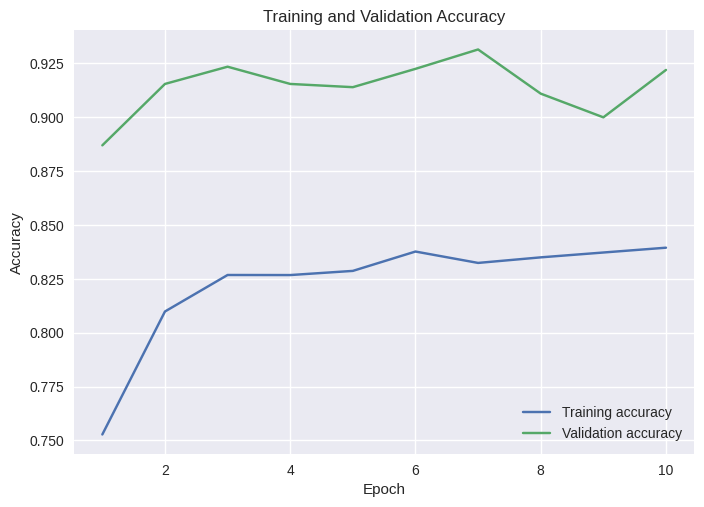

In [112]:
# load best model
model.load_weights(f"best_model_{model.name}.weights.h5")

# ------------------------
# ---     Plotting     ---
# ------------------------

# plot training history
history = np.genfromtxt(f"history_{model.name}.csv", delimiter=",", names=True)
# add plots below

# Plot training and validation accuracy
epochs = range(1, len(history['accuracy']) + 1) # assure plot starts on epoch 1 and not 0

plt.plot(epochs, history['accuracy'], label='Training accuracy')
plt.plot(epochs, history['val_accuracy'], label='Validation accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()


# Plot confussion matrix



In [113]:
# evaluate performance

print("Model performance :")
headers = ["", "Loss", "Accuracy", "Error rate [%]"]

table = [
    [
        "Train",
        *model.evaluate(x_train, y_train_onehot, verbose=0, batch_size=128),
        (1 - model.evaluate(x_train, y_train_onehot, verbose=0, batch_size=128)[1])
        * 100,
    ],
    [
        "Validation",
        *model.evaluate(x_valid, y_valid_onehot, verbose=0, batch_size=128),
        (1 - model.evaluate(x_valid, y_valid_onehot, verbose=0, batch_size=128)[1])
        * 100,
    ],
    [
        "Test",
        *model.evaluate(x_test, y_test_onehot, verbose=0, batch_size=128),
        (1 - model.evaluate(x_test, y_test_onehot, verbose=0, batch_size=128)[1]) * 100,
    ],
]

print(tabulate(table, headers=headers, tablefmt="orgtbl"))

Model performance :
|            |     Loss |   Accuracy |   Error rate [%] |
|------------+----------+------------+------------------|
| Train      | 0.465789 |   0.915683 |          8.43167 |
| Validation | 0.555601 |   0.9315   |          6.85    |
| Test       | 0.673492 |   0.90825  |          9.175   |


You can compare your own results with a variety of different models: http://yann.lecun.com/exdb/mnist/ and https://en.wikipedia.org/wiki/MNIST_database

The following codeblocks define some helper functions for plotting. You don't need to touch them

In [114]:
# @title
def plot_image(X, ax=None):
    """Plot an image X.

    Args:
        X (2D array): image, grayscale or RGB
        ax (None, optional): Description
    """
    if ax is None:
        ax = plt.gca()

    if (X.ndim == 2) or (X.shape[-1] == 1):
        ax.imshow(X.astype("uint8"), origin="upper", cmap=plt.cm.Greys)
    else:
        ax.imshow(X.astype("uint8"), origin="upper")

    ax.set(xticks=[], yticks=[])


def plot_prediction(Yp, X, y, classes=None, top_n=False):
    """Plot an image along with all or the top_n predictions.

    Args:
        Yp (1D array): predicted probabilities for each class
        X (2D array): image
        y (integer): true class label
        classes (1D array, optional): class names
        top_n (int, optional): number of top predictions to show
    """
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 3.2))
    fig.subplots_adjust(left=0.02, right=0.98, bottom=0.15, top=0.98, wspace=0.02)
    plot_image(X, ax1)

    if top_n:
        n = top_n
        s = np.argsort(Yp)[-top_n:]
    else:
        n = len(Yp)
        s = np.arange(n)[::-1]

    patches = ax2.barh(np.arange(n), Yp[s], align="center")
    ax2.set(xlim=(0, 1), xlabel="Probability", yticks=[])

    for iy, patch in zip(s, patches):
        if iy == y:
            patch.set_facecolor("C1")  # color correct patch

    if classes is None:
        classes = np.arange(0, np.size(Yp))

    for i in range(n):
        ax2.text(0.05, i, classes[s][i], ha="left", va="center")

    plt.show()


def plot_confusion(yp, y, classes=None, fname=None):
    """Plot confusion matrix for given true and predicted class labels

    Args:
        yp (1D array): predicted class labels
        y (1D array): true class labels
        classes (1D array): class names
        fname (str, optional): filename for saving the plot
    """
    if classes is None:
        n = max(max(yp), max(y)) + 1
        classes = np.arange(n)
    else:
        n = len(classes)

    bins = np.linspace(-0.5, n - 0.5, n + 1)
    C = np.histogram2d(y, yp, bins=bins)[0]
    C = C / np.sum(C, axis=0) * 100

    _ = plt.figure(figsize=(8, 8))
    plt.imshow(C, interpolation="nearest", vmin=0, vmax=100, cmap=plt.cm.YlGnBu)
    plt.gca().set_aspect("equal")
    cbar = plt.colorbar(shrink=0.8)
    cbar.set_label("Frequency %")
    plt.xlabel("Prediction")
    plt.ylabel("Truth")
    plt.xticks(range(n), classes, rotation="vertical")
    plt.yticks(range(n), classes)
    for x in range(n):
        for y in range(n):
            if np.isnan(C[x, y]):
                continue
            color = "white" if x == y else "black"
            plt.annotate(
                "%.1f" % (C[x, y]), xy=(y, x), color=color, ha="center", va="center"
            )

    plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


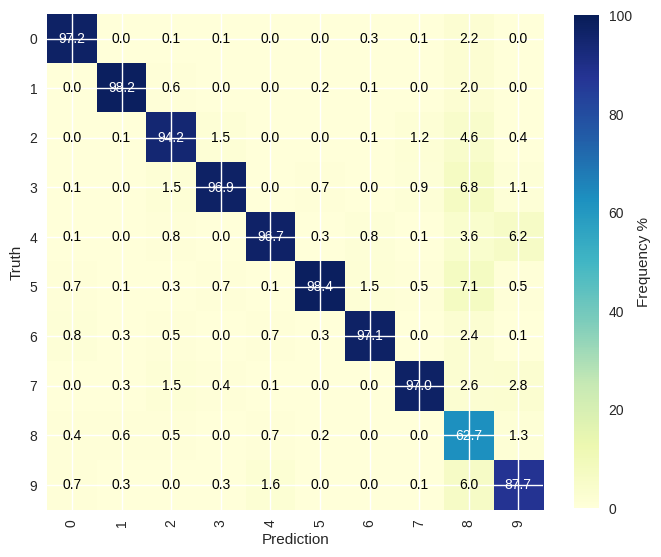

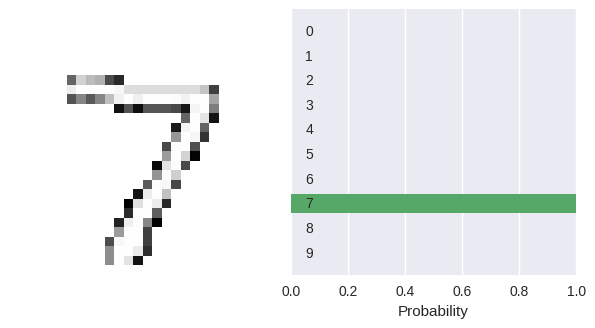

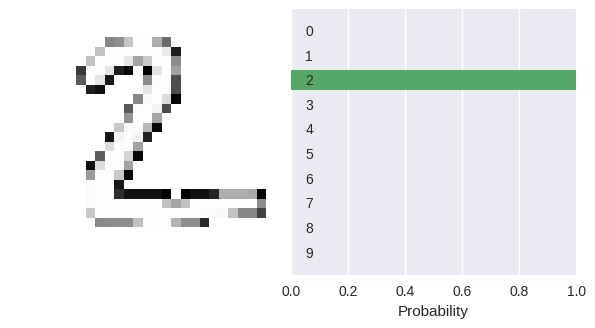

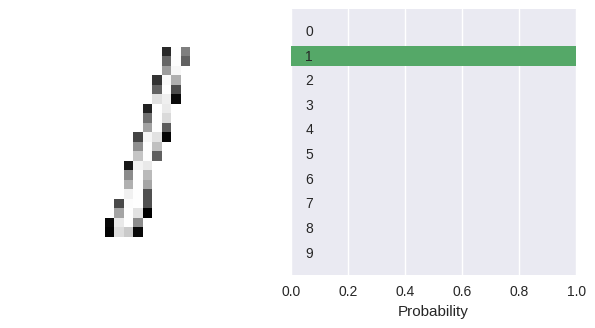

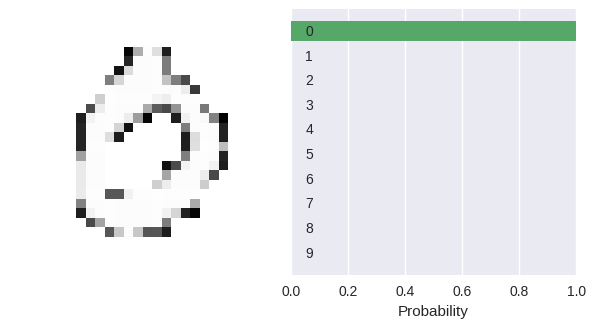

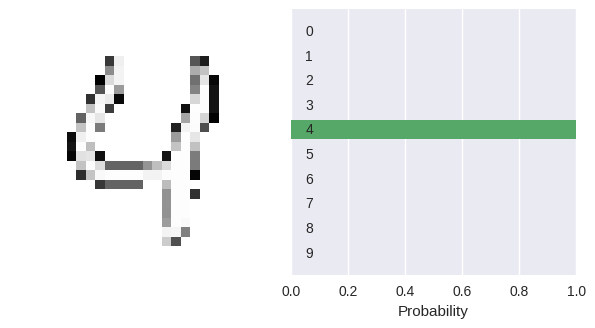

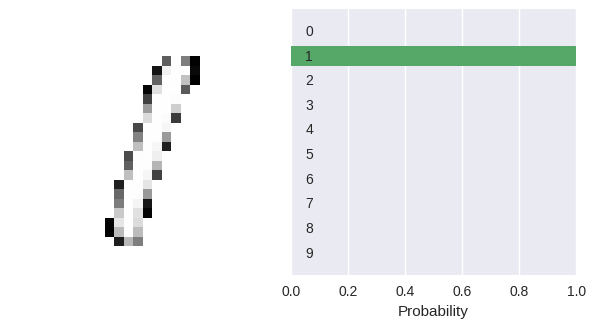

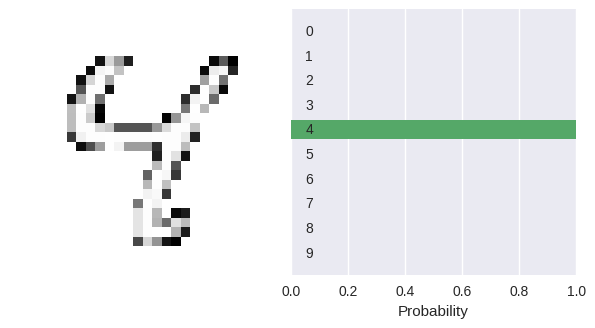

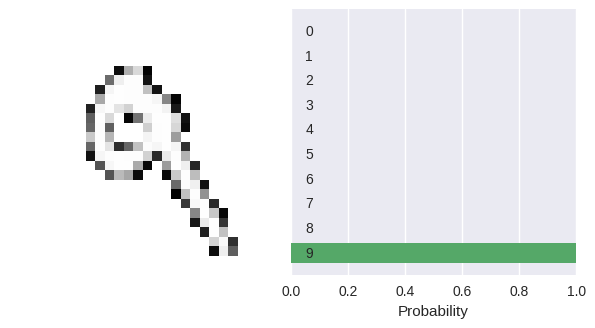

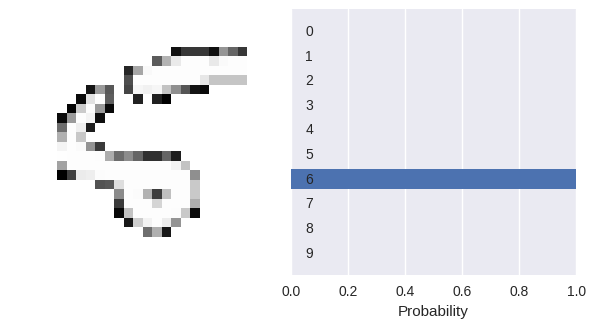

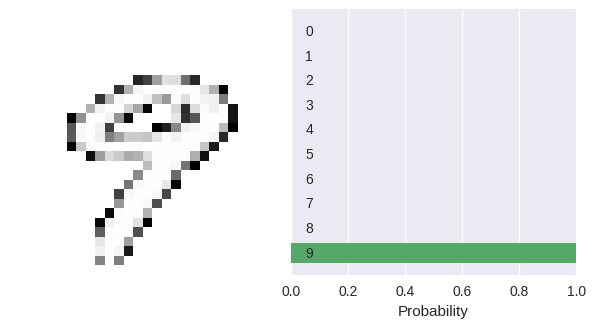

In [115]:
# plot a few examples, loop over test dataset:
# get missidentified samples
output = model.predict(x_test, batch_size=128)
labels = np.argmax(y_test_onehot, axis=1)
predictions = np.argmax(output, axis=1)
plot_confusion(predictions, labels)

for i in range(10): # loop over first 10 test samples
    plot_prediction(output[i],
                    255 * np.reshape(x_test[i], (28, 28)), # we need to reshape the data into an image and convert back to RGB color scale by multiplying with 255
                    labels[i])


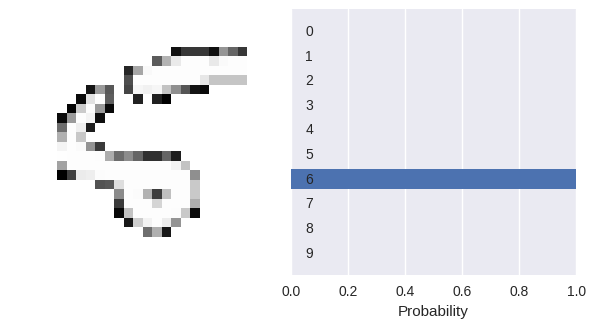

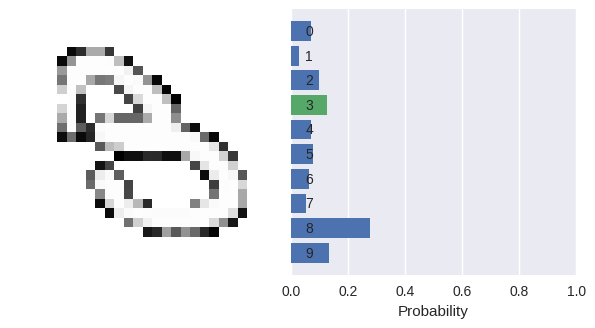

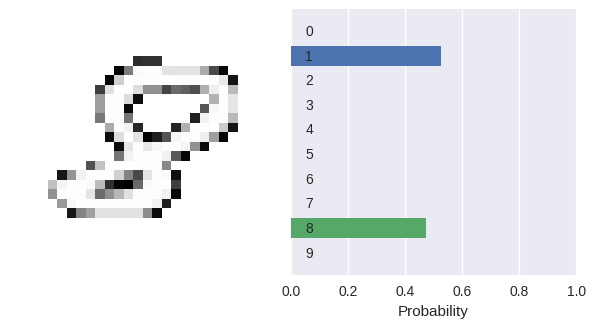

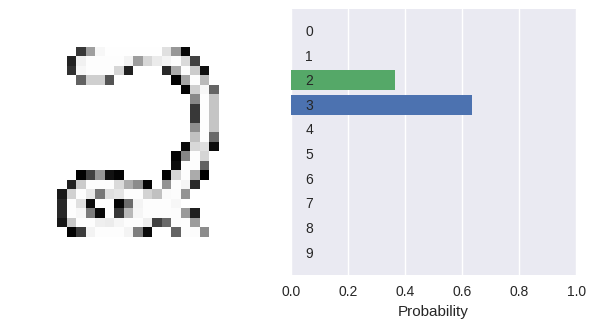

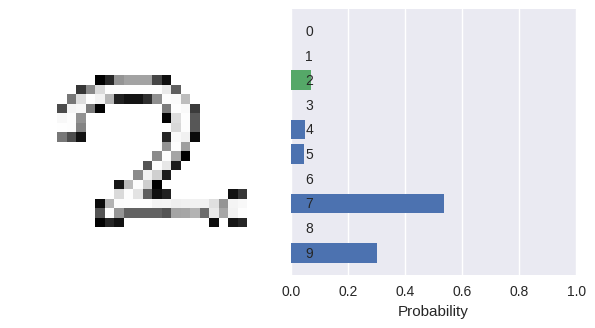

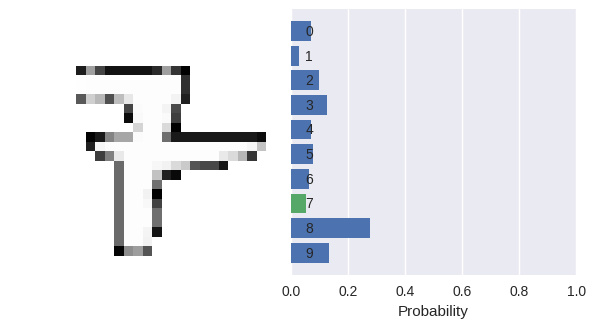

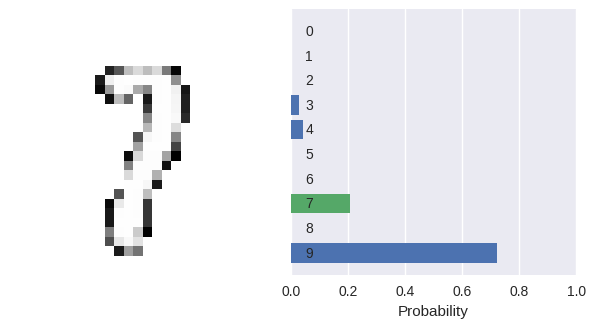

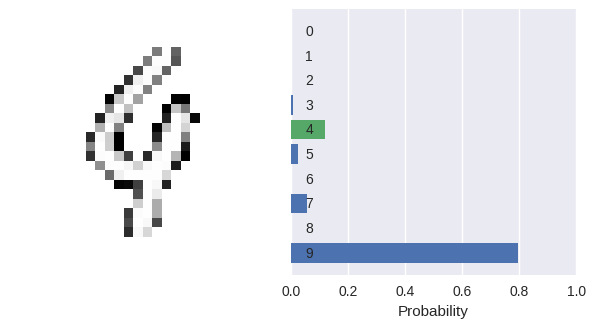

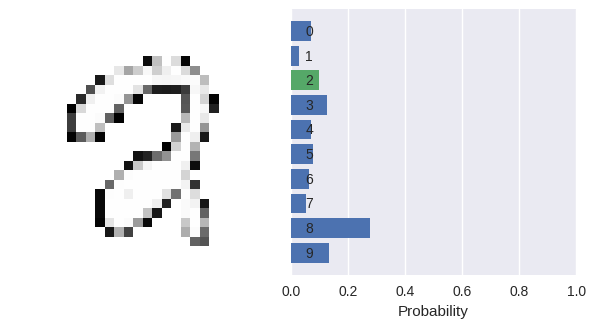

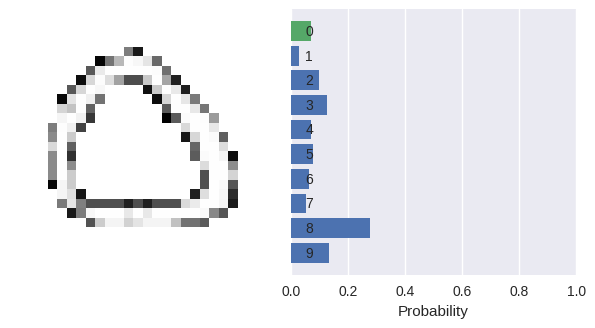

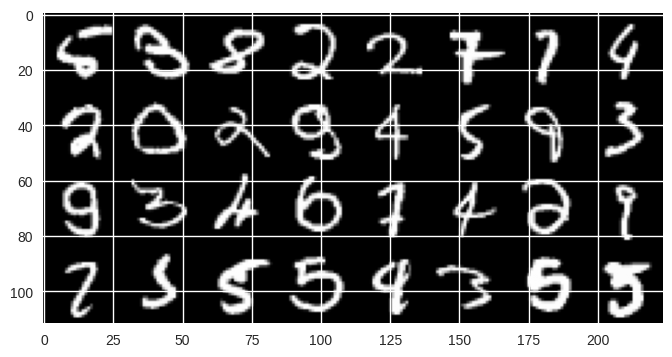

In [116]:
# now plot a few examples that were misclassified

indices_miss = np.nonzero(predictions != labels)[0]
x_missid = x_test[indices_miss]

for i in indices_miss[:10]:
    plot_prediction(output[i],
                    255 * np.reshape(x_test[i], (28, 28)), # we need to reshape the data into an image and convert back to RGB color scale by multiplying with 255
                    labels[i])

# or plot 32 of them in a joint plot
fig = plt.figure()
ax = fig.add_subplot(111)
plotdata = x_missid[:32]
plotdata = np.hstack(np.concatenate(np.reshape(plotdata, (4, 8, 28, 28)), axis=1))
ax.imshow(plotdata, cmap="gray")


**Grid search**

Let's search the two hyperparameters dropout and number of nodes. You can start from the template below.



In [136]:
dropout_values = [0.2, 0.3, 0.4, 0.5]
n_neurons_values = [32, 64, 96, 128, 192]
results_gridsearch = np.zeros((len(dropout_values), len(n_neurons_values), 2))
# Store test accuracy
test_accuracies = np.zeros(
    (len(dropout_values), len(n_neurons_values))
)
for iDrop, drop in enumerate(dropout_values):
  for iN, n_neurons in enumerate(n_neurons_values):

    model = tf.keras.models.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(n_neurons, activation='relu'),
        layers.Dropout(drop),
        layers.Dense(10, activation='softmax')
    ])

    model.compile(
        loss='categorical_crossentropy',
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=['accuracy']
    )

    results = model.fit(
        x_train, y_train_onehot,
        validation_data=(x_valid, y_valid_onehot),
        batch_size= 128,
        epochs=10,
        verbose=0
        )

    # Train loss and accuracy
    t = model.evaluate(x_valid, y_valid_onehot, verbose=0, batch_size=128)
    results_gridsearch[iDrop, iN] = t

    # Test loss and accuracy
    test_loss, test_acc = model.evaluate(x_test, y_test_onehot, verbose=0,batch_size=128)

    test_accuracies[iDrop, iN] = test_acc
    print(
        f"dropout = {drop:.2f}, {n_neurons} neurons -> "
        f"validation accuracy = {t[1]:.3f}, "
        f"test accuracy = {test_acc:.3f}, "
        f"test error rate = {100*(1-test_acc):.1f}%"
    )


dropout = 0.20, 32 neurons -> validation accuracy = 0.942, test accuracy = 0.910, test error rate = 9.0%
dropout = 0.20, 64 neurons -> validation accuracy = 0.941, test accuracy = 0.927, test error rate = 7.3%
dropout = 0.20, 96 neurons -> validation accuracy = 0.961, test accuracy = 0.942, test error rate = 5.8%
dropout = 0.20, 128 neurons -> validation accuracy = 0.961, test accuracy = 0.947, test error rate = 5.3%
dropout = 0.20, 192 neurons -> validation accuracy = 0.969, test accuracy = 0.956, test error rate = 4.4%
dropout = 0.30, 32 neurons -> validation accuracy = 0.899, test accuracy = 0.873, test error rate = 12.7%
dropout = 0.30, 64 neurons -> validation accuracy = 0.943, test accuracy = 0.924, test error rate = 7.6%
dropout = 0.30, 96 neurons -> validation accuracy = 0.964, test accuracy = 0.942, test error rate = 5.8%
dropout = 0.30, 128 neurons -> validation accuracy = 0.968, test accuracy = 0.943, test error rate = 5.7%
dropout = 0.30, 192 neurons -> validation accuracy 

**Random seach**

Now lets implement a random search. A random search allows us to scan more hyperparameters at once without more computing time. You can start from the template below.




In [135]:
N = 20 # number of trials
search = {
    'batch_size': np.random.choice([16, 32, 64, 128, 256], N),
    'num_neurons': np.random.choice([8, 32, 128, 256, 512], N),
    'learn_rate': np.random.choice([-5,-4, -3, -2, -1],N),
    'activation': np.random.choice(['relu', 'elu', 'sigmoid', 'tanh'], N),
    'dropout': np.random.choice([0.0, 0.1, 0.2, 0.3, 0.5, 0.6], N),
    'val_acc': np.zeros(N),
    'test_acc': np.zeros(N)
}

for i in range(N):

    # Get hyperparameters for this trial
    batch_size = int(search['batch_size'][i])
    num_neurons = int(search['num_neurons'][i])
    learning_rate = 10.0 ** int(search['learn_rate'][i])
    activation = search['activation'][i]
    dropout = float(search['dropout'][i])

  # you can access the current value of the hyperparameter with `search['batch_size'][i]`
    model = tf.keras.models.Sequential([
        layers.Input(shape=(784,)),
        layers.Dense(num_neurons, activation=activation),
        layers.Dropout(dropout),
        layers.Dense(10, activation='softmax')
    ])


    model.compile(
        loss='categorical_crossentropy',
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        metrics=['accuracy']
    )


    results = model.fit(
          x_train, y_train_onehot,
          validation_data=(x_valid, y_valid_onehot),
          batch_size= batch_size,
          epochs=10,
          verbose=0
        )

    # Validation accuracy
    search['val_acc'][i] = model.evaluate(x_valid, y_valid_onehot, verbose=0, batch_size=128)[1]

    # Test accuracy
    search['test_acc'][i] = model.evaluate(x_test, y_test_onehot, verbose=0, batch_size=128)[1]


    print(f"Iteration {i + 1}/{N}:")
    for key in search:
        print(f"\t{key}: {search[key][i]}")

    print(
        f"\t-> Validation accuracy = {search['val_acc'][i]:.3f}, "
        f"Test accuracy = {search['test_acc'][i]:.3f}, "
        f"Test error rate = {100 * (1 - search['test_acc'][i]):.1f}%"
    )


Iteration 1/20:
	batch_size: 32
	num_neurons: 256
	learn_rate: -1
	activation: elu
	dropout: 0.2
	val_acc: 0.10750000178813934
	test_acc: 0.1016250029206276
	-> Validation accuracy = 0.108, Test accuracy = 0.102, Test error rate = 89.8%
Iteration 2/20:
	batch_size: 16
	num_neurons: 32
	learn_rate: -1
	activation: tanh
	dropout: 0.1
	val_acc: 0.10199999809265137
	test_acc: 0.11112499982118607
	-> Validation accuracy = 0.102, Test accuracy = 0.111, Test error rate = 88.9%
Iteration 3/20:
	batch_size: 128
	num_neurons: 128
	learn_rate: -5
	activation: relu
	dropout: 0.0
	val_acc: 0.9079999923706055
	test_acc: 0.8532500267028809
	-> Validation accuracy = 0.908, Test accuracy = 0.853, Test error rate = 14.7%
Iteration 4/20:
	batch_size: 32
	num_neurons: 8
	learn_rate: -1
	activation: sigmoid
	dropout: 0.5
	val_acc: 0.18299999833106995
	test_acc: 0.1850000023841858
	-> Validation accuracy = 0.183, Test accuracy = 0.185, Test error rate = 81.5%
Iteration 5/20:
	batch_size: 64
	num_neurons: 12

**Investigating diffrent number of trials**


Repeat 1/3
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000


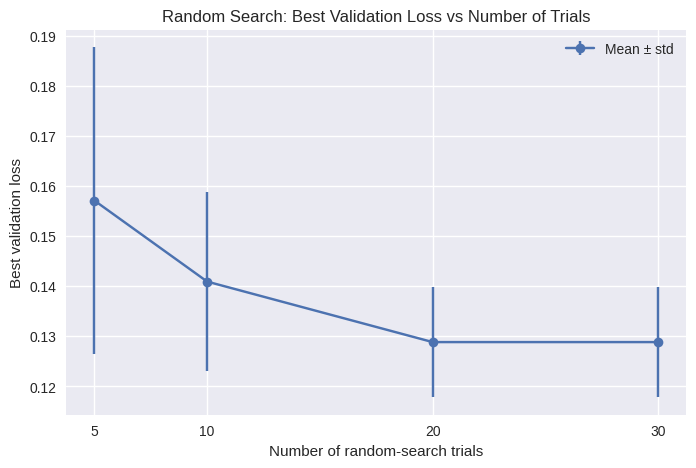

In [140]:
# Different numbers of random-search trials
N_values = [5, 10, 20, 30]

# Repeat each experiment 3 times
num_repeats = 3

# Store the best validation loss for each experiment
best_losses = np.zeros((len(N_values), num_repeats))


for j in range(num_repeats):
  print(f"\nRepeat {j + 1}/{num_repeats}")

  # Generate independent random hyperparameter combinations
  N_max = max(N_values)


  search = {
    'batch_size': np.random.choice([16, 32, 64, 128, 256], N_max),
    'num_neurons': np.random.choice([8, 32, 128, 256, 512], N_max),
    'learn_rate': np.random.choice([-5, -4, -3, -2, -1], N_max),
    'activation': np.random.choice(['relu', 'elu', 'sigmoid', 'tanh'], N_max),
    'dropout': np.random.choice([0.0, 0.1, 0.2, 0.3, 0.5, 0.6], N_max),
    'val_loss': np.zeros(N_max)}

  # Train each sampled model once
  for i in range(N_max):

      batch_size = int(search['batch_size'][i])
      num_neurons = int(search['num_neurons'][i])
      learning_rate = 10.0 ** int(search['learn_rate'][i])
      activation = search['activation'][i]
      dropout = float(search['dropout'][i])

      model = tf.keras.models.Sequential([
          layers.Input(shape=(784,)),
          layers.Dense(num_neurons, activation=activation),
          layers.Dropout(dropout),
          layers.Dense(10, activation='softmax')
      ])

      model.compile(
          loss='categorical_crossentropy',
          optimizer=tf.keras.optimizers.Adam(
              learning_rate=learning_rate
          ),
          metrics=['accuracy']
      )

      model.fit(
          x_train, y_train_onehot,
          validation_data=(x_valid, y_valid_onehot),
          batch_size=batch_size,
          epochs=10,
          verbose=0
      )

      # Evaluating the validation loss
      val_loss, val_acc = model.evaluate(x_valid, y_valid_onehot, verbose=0)

      search['val_loss'][i] = val_loss

      # best loss for N-trials

      for k, N in enumerate(N_values):

        best_losses[k, j] = np.min(search['val_loss'][:N])

        print(f"N = {N:2d}, "f"best validation loss = {best_losses[k, j]:.4f}")

  # Calculate mean and standard deviation
  mean_loss = np.mean(best_losses, axis=1)
  std_loss = np.std(best_losses, axis=1)

  # Plot results
plt.figure(figsize=(8, 5))

plt.errorbar(
    N_values,
    mean_loss,
    yerr=std_loss,
    fmt='o-',
    capsize=5,
    label='Mean ± std'
)

plt.xlabel('Number of random-search trials')
plt.ylabel('Best validation loss')
plt.title('Random Search: Best Validation Loss vs Number of Trials')
plt.xticks(N_values)
plt.legend()
plt.grid(True)
plt.show()



# Results

The first part of the exrecise was to implement a neural network consisting of one layer to classify hand written numbers form 28x28 pixel images. The training and validation accuracy was then plotted as a function of number of epochs. For the training 10 epochs where run with batches of 5.
The confussion matrix and examples of correctly and incorectly classified numbers where also plotted. The confussion matrix tells us how well the classification model predict it's classes. It is a usefull tool to help understand which predictions are correct and which classes the neural network confuses with eachother.

**Network structure 0: hidden layers=1, number of neurons=128 (without dropout)**

No dropout was used for this first experiment run.

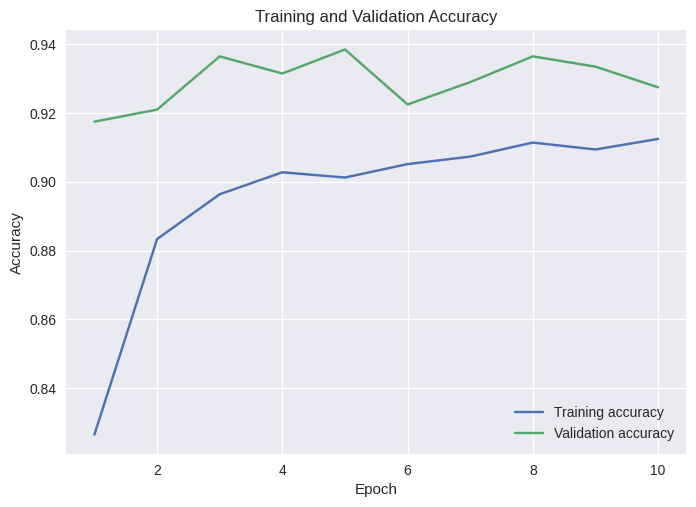

In [ ]:
Model performance :
|            |     Loss |   Accuracy |   Error rate [%] |
|------------+----------+------------+------------------|
| Train      | 0.398702 |   0.919133 |          8.08667 |
| Validation | 0.295065 |   0.9385   |          6.15    |
| Test       | 0.570165 |   0.90925  |          9.075   |

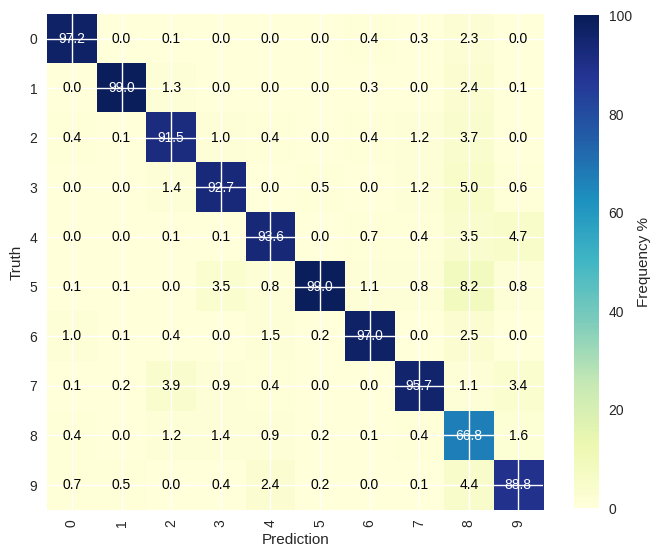

**Network structure 1: Hidden layers = 1, number of neurons = 128**

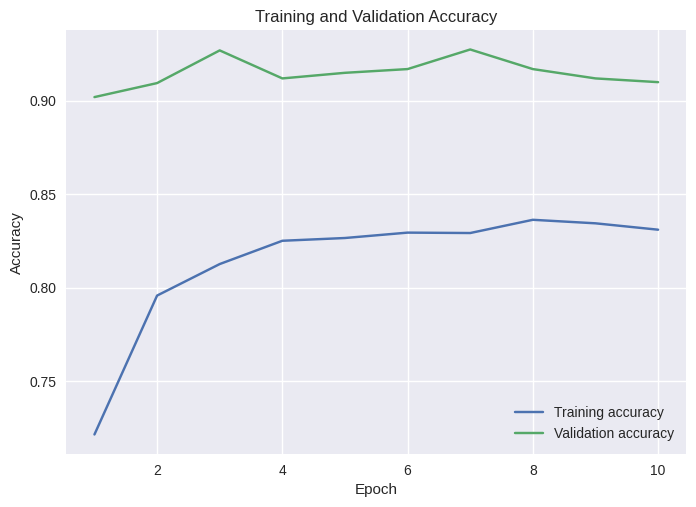

In [ ]:
Model performance :
|            |     Loss |   Accuracy |   Error rate [%] |
|------------+----------+------------+------------------|
| Train      | 0.576676 |   0.914117 |          8.58833 |
| Validation | 0.511204 |   0.9275   |          7.25    |
| Test       | 0.839193 |   0.903125 |          9.6875  |

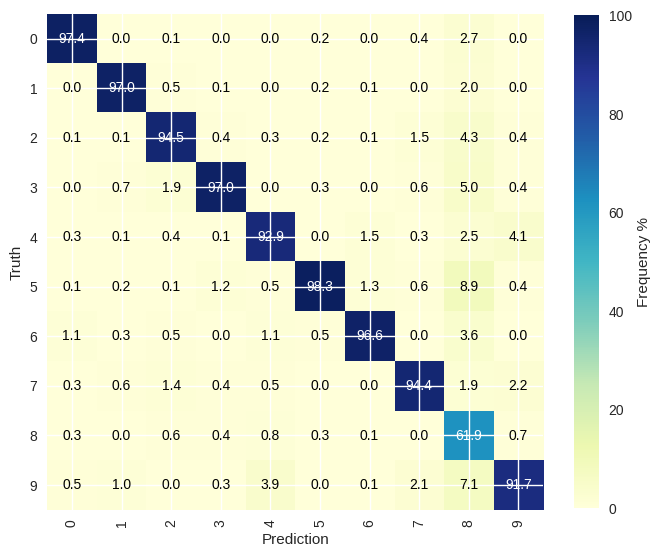

Adding dropout showed to decrease the performance of the model slightly. This can be expected since dropout increases randomness to avoid overfitting in the model. This should help decrease the generalization gap. Without dropout the generalization gap is 0.009883, and with dropot the generalization gap is 0.010092. Dropout did not seem you yielld a smaller generalization gap, however the model is not that complex with only one hidden layer so it might not influence to such a large extent for this relatively simple network.

**Network structure 2: hidden layers=2, number of neurons=128**

In the next neural network the umber of layers where increased to 2 to se weather or not this improved the accuracy of the model.

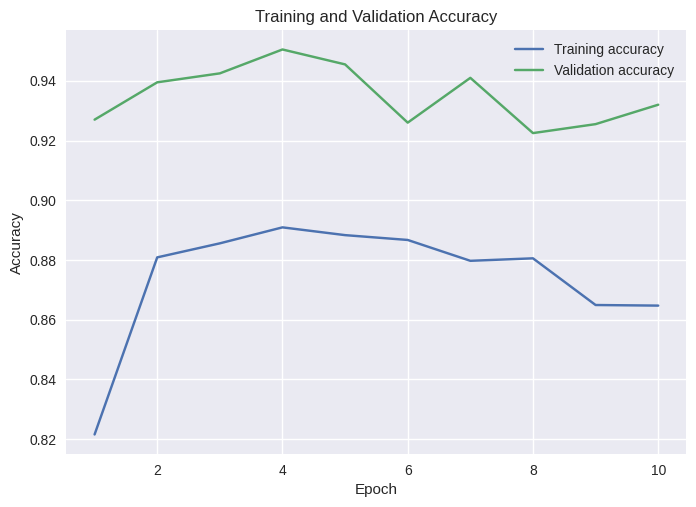

In [ ]:
Model performance :
|            |     Loss |   Accuracy |   Error rate [%] |
|------------+----------+------------+------------------|
| Train      | 0.281117 |   0.940533 |          5.94667 |
| Validation | 0.301736 |   0.9505   |          4.95    |
| Test       | 0.384118 |   0.933625 |          6.6375  |

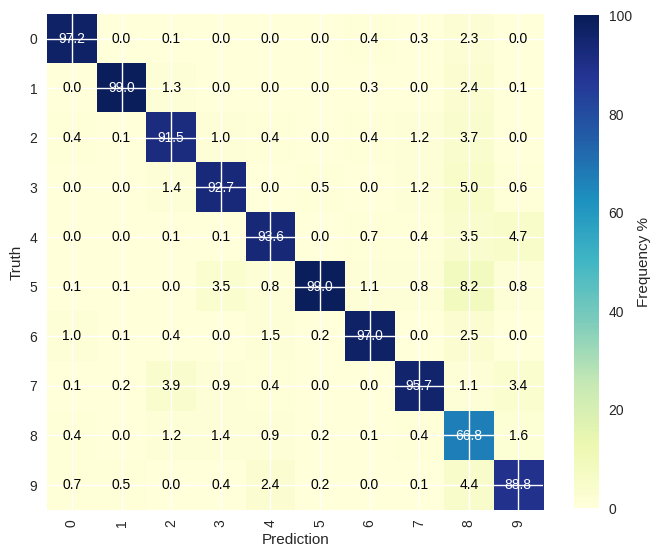

When increasing the number of layers the accuracy increased significantly. This happend for all three datasets. Most significantly is the increase in the test accuracy which incresed by rougly 3 percent. Thus adding a layer showed to significantly be effective for classifying new unseen data.

**Network structure 2: hidden layers = 1, number of neurons = 164**

In the next training set I let the number of hidden layers be 1 and instead investigated the influence of increasing the number of hidden layers.

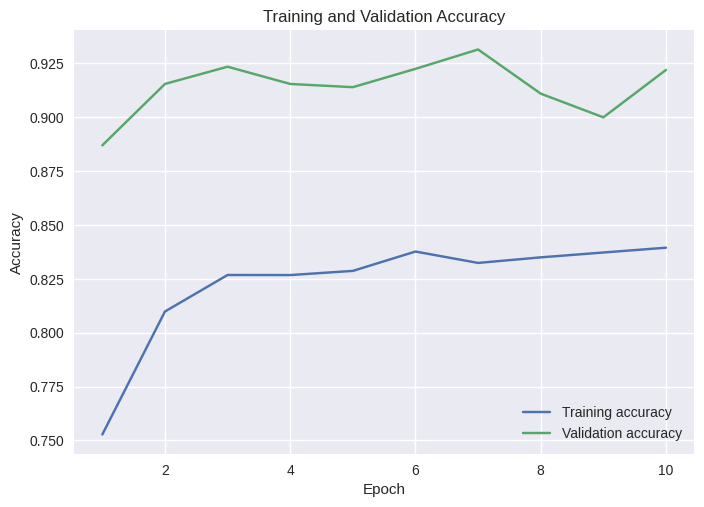

In [ ]:


Model performance :
|            |     Loss |   Accuracy |   Error rate [%] |
|------------+----------+------------+------------------|
| Train      | 0.465789 |   0.915683 |          8.43167 |
| Validation | 0.555601 |   0.9315   |          6.85    |
| Test       | 0.673492 |   0.90825  |          9.175   |

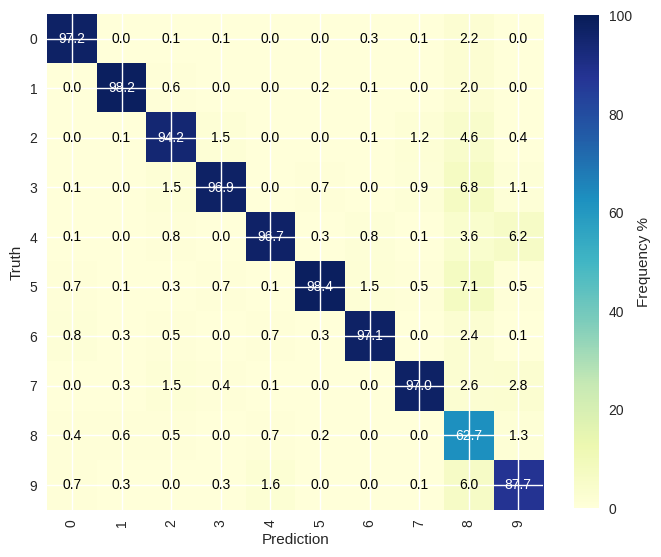

## **Grid search**

In the grid search I tested diffrent values for the number of nodes and the drop out rate. I changed the batch size to 128 to assure faster training since we now where testing for 5x5=20 diffrent training sessions. When using GPU for the training this significantly increases runtime since it allows tensorflow to process more images simultaneously.

dropout = 0.20, 32 neurons -> accuracy 0.936, error rate = 6.4%

dropout = 0.20, 64 neurons -> accuracy 0.952, error rate = 4.8%

dropout = 0.20, 96 neurons -> accuracy 0.962, error rate = 3.8%

dropout = 0.20, 128 neurons -> accuracy 0.965, error rate = 3.5%

dropout = 0.20, 192 neurons -> accuracy 0.968, error rate = 3.2%

dropout = 0.30, 32 neurons -> accuracy 0.919, error rate = 8.1%

dropout = 0.30, 64 neurons -> accuracy 0.945, error rate = 5.5%

dropout = 0.30, 96 neurons -> accuracy 0.951, error rate = 4.9%

dropout = 0.30, 128 neurons -> accuracy 0.959, error rate = 4.1%

dropout = 0.30, 192 neurons -> accuracy 0.961, error rate = 3.9%

dropout = 0.40, 32 neurons -> accuracy 0.764, error rate = 23.6%

dropout = 0.40, 64 neurons -> accuracy 0.942, error rate = 5.8%

dropout = 0.40, 96 neurons -> accuracy 0.948, error rate = 5.2%

dropout = 0.40, 128 neurons -> accuracy 0.961, error rate = 3.9%

dropout = 0.40, 192 neurons -> accuracy 0.961, error rate = 3.9%

dropout = 0.50, 32 neurons -> accuracy 0.821, error rate = 17.9%

dropout = 0.50, 64 neurons -> accuracy 0.914, error rate = 8.6%

dropout = 0.50, 96 neurons -> accuracy 0.936, error rate = 6.4%

dropout = 0.50, 128 neurons -> accuracy 0.947, error rate = 5.3%

dropout = 0.50, 192 neurons -> accuracy 0.955, error rate = 4.5%

** Including test accuracy**

dropout = 0.20, 32 neurons -> validation accuracy = 0.942, test accuracy = 0.910, test error rate = 9.0%

dropout = 0.20, 64 neurons -> validation accuracy = 0.941, test accuracy = 0.927, test error rate = 7.3%

dropout = 0.20, 96 neurons -> validation accuracy = 0.961, test accuracy = 0.942, test error rate = 5.8%

dropout = 0.20, 128 neurons -> validation accuracy = 0.961, test accuracy = 0.947, test error rate = 5.3%

dropout = 0.20, 192 neurons -> validation accuracy = 0.969, test accuracy = 0.956, test error rate = 4.4%

dropout = 0.30, 32 neurons -> validation accuracy = 0.899, test accuracy = 0.873, test error rate = 12.7%

dropout = 0.30, 64 neurons -> validation accuracy = 0.943, test accuracy = 0.924, test error rate = 7.6%

dropout = 0.30, 96 neurons -> validation accuracy = 0.964, test accuracy = 0.942, test error rate = 5.8%

dropout = 0.30, 128 neurons -> validation accuracy = 0.968, test accuracy = 0.943, test error rate = 5.7%

dropout = 0.30, 192 neurons -> validation accuracy = 0.962, test accuracy = 0.951, test error rate = 4.9%

dropout = 0.40, 32 neurons -> validation accuracy = 0.900, test accuracy = 0.861, test error rate = 13.9%

dropout = 0.40, 64 neurons -> validation accuracy = 0.943, test accuracy = 0.916, test error rate = 8.4%

dropout = 0.40, 96 neurons -> validation accuracy = 0.942, test accuracy = 0.929, test error rate = 7.1%

dropout = 0.40, 128 neurons -> validation accuracy = 0.955, test accuracy = 0.938, test error rate = 6.2%

dropout = 0.40, 192 neurons -> validation accuracy = 0.967, test accuracy = 0.942, test error rate = 5.8%

dropout = 0.50, 32 neurons -> validation accuracy = 0.823, test accuracy = 0.743, test error rate = 25.7%

dropout = 0.50, 64 neurons -> validation accuracy = 0.934, test accuracy = 0.897, test error rate = 10.3%

dropout = 0.50, 96 neurons -> validation accuracy = 0.945, test accuracy = 0.913, test error rate = 8.7%

dropout = 0.50, 128 neurons -> validation accuracy = 0.953, test accuracy = 0.934, test error rate = 6.6%

dropout = 0.50, 192 neurons -> validation accuracy = 0.953, test accuracy = 0.938, test error rate = 6.2%

The best accuracy was obtained for dropout = 0.20, 192 neurons -> accuracy 0.968, error rate = 3.2%. Thus letting dropout stay at the lower end of the bound with a more complex network showed to yielld higher accuracy. A grid search showed to take some time. In this search only 2 diffrent parameters with five diffrent values where tested for. Thus if we want to test more combinations of diffrent parameters this will become increasinging time inefficient. Thus to be able to investigate more parameeter combinations while avoiding long run times a random sampling is performed.

## **Random sampling**

Random sampling will investigate 5 diffrent hyperparameters such as number of neurons, dropot fraction, learning rate and batch size. Random sampling is then made between these diffrent choices and their accuracy with corresponding error rate is the computed. 20 diffrent random choices where computed.

Iteration 1/20:
	batch_size: 32
	num_neurons: 256
	learn_rate: -1
	activation: elu
	dropout: 0.2
	val_acc: 0.10750000178813934
	test_acc: 0.1016250029206276
	-> Validation accuracy = 0.108, Test accuracy = 0.102, Test error rate = 89.8%

Iteration 2/20:
	batch_size: 16
	num_neurons: 32
	learn_rate: -1
	activation: tanh
	dropout: 0.1
	val_acc: 0.10199999809265137
	test_acc: 0.11112499982118607
	-> Validation accuracy = 0.102, Test accuracy = 0.111, Test error rate = 88.9%

Iteration 3/20:
	batch_size: 128
	num_neurons: 128
	learn_rate: -5
	activation: relu
	dropout: 0.0
	val_acc: 0.9079999923706055
	test_acc: 0.8532500267028809
	-> Validation accuracy = 0.908, Test accuracy = 0.853, Test error rate = 14.7%

Iteration 4/20:
	batch_size: 32
	num_neurons: 8
	learn_rate: -1
	activation: sigmoid
	dropout: 0.5
	val_acc: 0.18299999833106995
	test_acc: 0.1850000023841858
	-> Validation accuracy = 0.183, Test accuracy = 0.185, Test error rate = 81.5%

Iteration 5/20:
	batch_size: 64
	num_neurons: 128
	learn_rate: -1
	activation: tanh
	dropout: 0.5
	val_acc: 0.15199999511241913
	test_acc: 0.1861249953508377
	-> Validation accuracy = 0.152, Test accuracy = 0.186, Test error rate = 81.4%

Iteration 6/20:
	batch_size: 128
	num_neurons: 256
	learn_rate: -1
	activation: relu
	dropout: 0.3
	val_acc: 0.10750000178813934
	test_acc: 0.10187499970197678
	-> Validation accuracy = 0.108, Test accuracy = 0.102, Test error rate = 89.8%

Iteration 7/20:
	batch_size: 256
	num_neurons: 32
	learn_rate: -3
	activation: elu
	dropout: 0.1
	val_acc: 0.925000011920929
	test_acc: 0.8896250128746033
	-> Validation accuracy = 0.925, Test accuracy = 0.890, Test error rate = 11.0%

Iteration 8/20:
	batch_size: 16
	num_neurons: 32
	learn_rate: -2
	activation: elu
	dropout: 0.0
	val_acc: 0.10750000178813934
	test_acc: 0.1016250029206276
	-> Validation accuracy = 0.108, Test accuracy = 0.102, Test error rate = 89.8%

Iteration 9/20:
	batch_size: 256
	num_neurons: 512
	learn_rate: -4
	activation: relu
	dropout: 0.3
	val_acc: 0.965499997138977
	test_acc: 0.9507499933242798
	-> Validation accuracy = 0.965, Test accuracy = 0.951, Test error rate = 4.9%

Iteration 10/20:
	batch_size: 128
	num_neurons: 32
	learn_rate: -3
	activation: sigmoid
	dropout: 0.2
	val_acc: 0.9309999942779541
	test_acc: 0.9100000262260437
	-> Validation accuracy = 0.931, Test accuracy = 0.910, Test error rate = 9.0%

Iteration 11/20:
	batch_size: 128
	num_neurons: 512
	learn_rate: -1
	activation: elu
	dropout: 0.3
	val_acc: 0.11500000208616257
	test_acc: 0.1132500022649765
	-> Validation accuracy = 0.115, Test accuracy = 0.113, Test error rate = 88.7%

Iteration 12/20:
	batch_size: 128
	num_neurons: 8
	learn_rate: -5
	activation: elu
	dropout: 0.3
	val_acc: 0.08399999886751175
	test_acc: 0.09537500143051147
	-> Validation accuracy = 0.084, Test accuracy = 0.095, Test error rate = 90.5%

Iteration 13/20:
	batch_size: 256
	num_neurons: 256
	learn_rate: -1
	activation: elu
	dropout: 0.1
	val_acc: 0.10100000351667404
	test_acc: 0.09437499940395355
	-> Validation accuracy = 0.101, Test accuracy = 0.094, Test error rate = 90.6%

Iteration 14/20:
	batch_size: 128
	num_neurons: 512
	learn_rate: -2
	activation: relu
	dropout: 0.2
	val_acc: 0.4390000104904175
	test_acc: 0.40299999713897705
	-> Validation accuracy = 0.439, Test accuracy = 0.403, Test error rate = 59.7%

Iteration 15/20:
	batch_size: 256
	num_neurons: 8
	learn_rate: -1
	activation: tanh
	dropout: 0.3
	val_acc: 0.19949999451637268
	test_acc: 0.20475000143051147
	-> Validation accuracy = 0.199, Test accuracy = 0.205, Test error rate = 79.5%

Iteration 16/20:
	batch_size: 128
	num_neurons: 32
	learn_rate: -5
	activation: elu
	dropout: 0.0
	val_acc: 0.637499988079071
	test_acc: 0.5733749866485596
	-> Validation accuracy = 0.637, Test accuracy = 0.573, Test error rate = 42.7%

Iteration 17/20:
	batch_size: 64
	num_neurons: 32
	learn_rate: -2
	activation: tanh
	dropout: 0.0
	val_acc: 0.765999972820282
	test_acc: 0.7153750061988831
	-> Validation accuracy = 0.766, Test accuracy = 0.715, Test error rate = 28.5%

Iteration 18/20:
	batch_size: 128
	num_neurons: 8
	learn_rate: -1
	activation: sigmoid
	dropout: 0.5
	val_acc: 0.11500000208616257
	test_acc: 0.11337500065565109
	-> Validation accuracy = 0.115, Test accuracy = 0.113, Test error rate = 88.7%

Iteration 19/20:
	batch_size: 256
	num_neurons: 32
	learn_rate: -2
	activation: elu
	dropout: 0.2
	val_acc: 0.3970000147819519
	test_acc: 0.3777500092983246
	-> Validation accuracy = 0.397, Test accuracy = 0.378, Test error rate = 62.2%

Iteration 20/20:
	batch_size: 32
	num_neurons: 8
	learn_rate: -4
	activation: elu
	dropout: 0.2
	val_acc: 0.4410000145435333
	test_acc: 0.3935000002384186
	-> Validation accuracy = 0.441, Test accuracy = 0.394, Test error rate = 60.6%

In regards to test accuracy the best combination of hyperparameters was obtasined for Iteration 9/20:

	batch_size: 256
	num_neurons: 512
	learn_rate: -4
	activation: relu
	dropout: 0.3
	val_acc: 0.965499997138977
	test_acc: 0.9507499933242798
	-> Validation accuracy = 0.965, Test accuracy = 0.951, Test error rate = 4.9%

  However it should be noted that when for tuning hyperaparameters the validation error should be used when comparing hyperparameters. The test data should only be used once when evaluating the final performance of the model with the choosen hyperparameters. However iteration 9 also yielded the highest validation accuracy and for a normal hyperparameter selection this model chould thus be choosen.

## **Number of trials necessary**


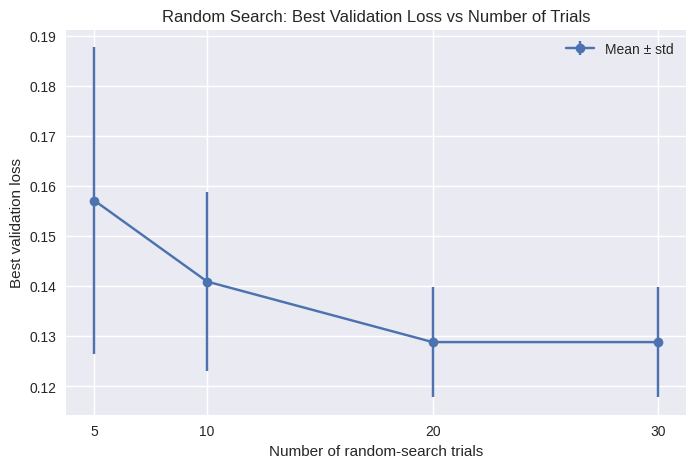

From the plot it seems that it is sufficient to only use 20 trials to find a good combination of hyperparameters. The validation loss stayed constant when increasing to 30 trials. It is thus only necessary to compoutue 20 trials and thus avoiding long computation times for the hyperparameter tuning.

**Output:**


Repeat 1/3
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1613
N = 10, best validation loss = 0.1613
N = 20, best validation loss = 0.1250
N = 30, best validation loss = 0.1250

Repeat 2/3
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1177
N = 10, best validation loss = 0.1177
N = 20, best validation loss = 0.1177
N = 30, best validation loss = 0.1177

Repeat 3/3
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.0000
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.0000
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.0000
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.0000
N =  5, best validation loss = 0.1923
N = 10, best validation loss = 0.1438
N = 20, best validation loss = 0.1438
N = 30, best validation loss = 0.1438